# Partie 4 – Analyse de panier moyen et produits achetés ensemble

Objectif : analyser le panier moyen des clients ClassicModels et identifier les produits fréquemment achetés ensemble pour optimiser les stratégies de cross-selling et de merchandising.

Analyses à réaliser :
- **Panier moyen** : montant moyen par commande, évolution dans le temps
- **Distribution du panier moyen** : analyse des différents segments de paniers
- **Produits achetés ensemble** : identification des associations de produits (co-occurrence)
- **Top associations de produits** : paires de produits les plus fréquemment commandées ensemble
- **Analyse par gamme de produits** : produits de la même gamme achetés ensemble

Nous utiliserons MySQL comme source de données et Python (pandas, matplotlib, seaborn) pour l'analyse et la visualisation.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import fetch_dataframe

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

## Extraction des données de commandes

On extrait les données des commandes avec les produits pour analyser le panier moyen et les associations de produits.

In [3]:
# Requête pour extraire les données de commandes avec produits
query_orders = """
SELECT
    o.orderNumber,
    o.orderDate,
    o.status,
    c.customerNumber,
    c.customerName,
    p.productCode,
    p.productName,
    p.productLine,
    od.quantityOrdered,
    od.priceEach,
    (od.quantityOrdered * od.priceEach) AS montant_ligne
FROM orders o
JOIN orderdetails od ON od.orderNumber = o.orderNumber
JOIN products p ON p.productCode = od.productCode
JOIN customers c ON c.customerNumber = o.customerNumber
WHERE o.status = 'Shipped'
ORDER BY o.orderNumber, p.productCode;
"""

df_orders = fetch_dataframe(query_orders)
df_orders["orderDate"] = pd.to_datetime(df_orders["orderDate"])

print(f"Nombre total de lignes de commande : {len(df_orders)}")
print(f"Nombre de commandes uniques : {df_orders['orderNumber'].nunique()}")
print(f"Nombre de produits uniques : {df_orders['productCode'].nunique()}")
df_orders.head()

Nombre total de lignes de commande : 2771
Nombre de commandes uniques : 303
Nombre de produits uniques : 109


C:\Users\bourbia\Desktop\python sql project\src\database\connection.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


,orderNumber,orderDate,status,customerNumber,customerName,productCode,productName,productLine,quantityOrdered,priceEach,montant_ligne
0,10100,2003-01-06,Shipped,363,Online Diecast Creations Co.,S18_1749,1917 Grand Touring Sedan,Vintage Cars,30,136.00,4080.00
1,10100,2003-01-06,Shipped,363,Online Diecast Creations Co.,S18_2248,1911 Ford Town Car,Vintage Cars,50,55.09,2754.50
2,10100,2003-01-06,Shipped,363,Online Diecast Creations Co.,S18_4409,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,22,75.46,1660.12
3,10100,2003-01-06,Shipped,363,Online Diecast Creations Co.,S24_3969,1936 Mercedes Benz 500k Roadster,Vintage Cars,49,35.29,1729.21
4,10101,2003-01-09,Shipped,128,"Blauer See Auto, Co.",S18_2325,1932 Model A Ford J-Coupe,Vintage Cars,25,108.06,2701.50


## Analyse du panier moyen

Calcul du panier moyen par commande et analyse de sa distribution.

In [4]:
# Calcul du montant total par commande
basket_analysis = df_orders.groupby('orderNumber').agg({
    'montant_ligne': 'sum',
    'productCode': 'count',
    'orderDate': 'first',
    'customerNumber': 'first',
    'customerName': 'first'
}).reset_index()

basket_analysis.columns = ['orderNumber', 'montant_total', 'nb_produits', 'orderDate', 'customerNumber', 'customerName']

# Calcul du panier moyen global
panier_moyen_global = basket_analysis['montant_total'].mean()
panier_median = basket_analysis['montant_total'].median()

print("=" * 80)
print("STATISTIQUES DU PANIER MOYEN")
print("=" * 80)
print(f"Panier moyen global : ${panier_moyen_global:,.2f}")
print(f"Panier médian : ${panier_median:,.2f}")
print(f"Panier minimum : ${basket_analysis['montant_total'].min():,.2f}")
print(f"Panier maximum : ${basket_analysis['montant_total'].max():,.2f}")
print(f"Écart-type : ${basket_analysis['montant_total'].std():,.2f}")
print(f"\nNombre moyen de produits par commande : {basket_analysis['nb_produits'].mean():.2f}")
print(f"Nombre médian de produits par commande : {basket_analysis['nb_produits'].median():.2f}")

basket_analysis.head()

STATISTIQUES DU PANIER MOYEN
Panier moyen global : $29,257.74
Panier médian : $30,253.75
Panier minimum : $615.45
Panier maximum : $67,392.85
Écart-type : $15,912.00

Nombre moyen de produits par commande : 9.15
Nombre médian de produits par commande : 9.00


,orderNumber,montant_total,nb_produits,orderDate,customerNumber,customerName
0,10100,10223.83,4,2003-01-06,363,Online Diecast Creations Co.
1,10101,10549.01,4,2003-01-09,128,"Blauer See Auto, Co."
2,10102,5494.78,2,2003-01-10,181,Vitachrome Inc.
3,10103,50218.95,16,2003-01-29,121,Baane Mini Imports
4,10104,40206.20,13,2003-01-31,141,Euro+ Shopping Channel


## Interprétation des statistiques du panier moyen

**Panier moyen : $29,258**
- **Valeur élevée** : Indique que les clients dépensent en moyenne près de $30K par commande, signe d'un positionnement premium
- **Médiane proche de la moyenne ($30,254)** : Distribution relativement équilibrée, pas de forte asymétrie

**Variabilité importante :**
- **Écart-type : $15,912** : Grande dispersion des montants (54% de la moyenne)
- **Écart min-max : $615 à $67,393** : Écart de 109x entre le panier le plus faible et le plus élevé
- **Implication** : Clientèle hétérogène avec des besoins et budgets très variés

**Panier moyen de 9,15 produits :**
- **Volume élevé** : Les clients achètent en moyenne 9 produits par commande
- **Opportunité de cross-selling** : Les clients sont ouverts à acheter plusieurs produits ensemble
- **Médiane à 9 produits** : Comportement cohérent, la moitié des commandes contient 9 produits ou plus

**Insights stratégiques :**
- **Positionnement premium confirmé** : Panier moyen élevé justifie une stratégie haut de gamme
- **Hétérogénéité clientèle** : Nécessité de segmenter l'offre (entrée de gamme + premium)
- **Potentiel cross-selling** : 9 produits/commande = opportunité d'augmenter encore le panier moyen

## Visualisation de la distribution du panier moyen

Graphiques montrant la distribution des montants de panier et l'évolution dans le temps.

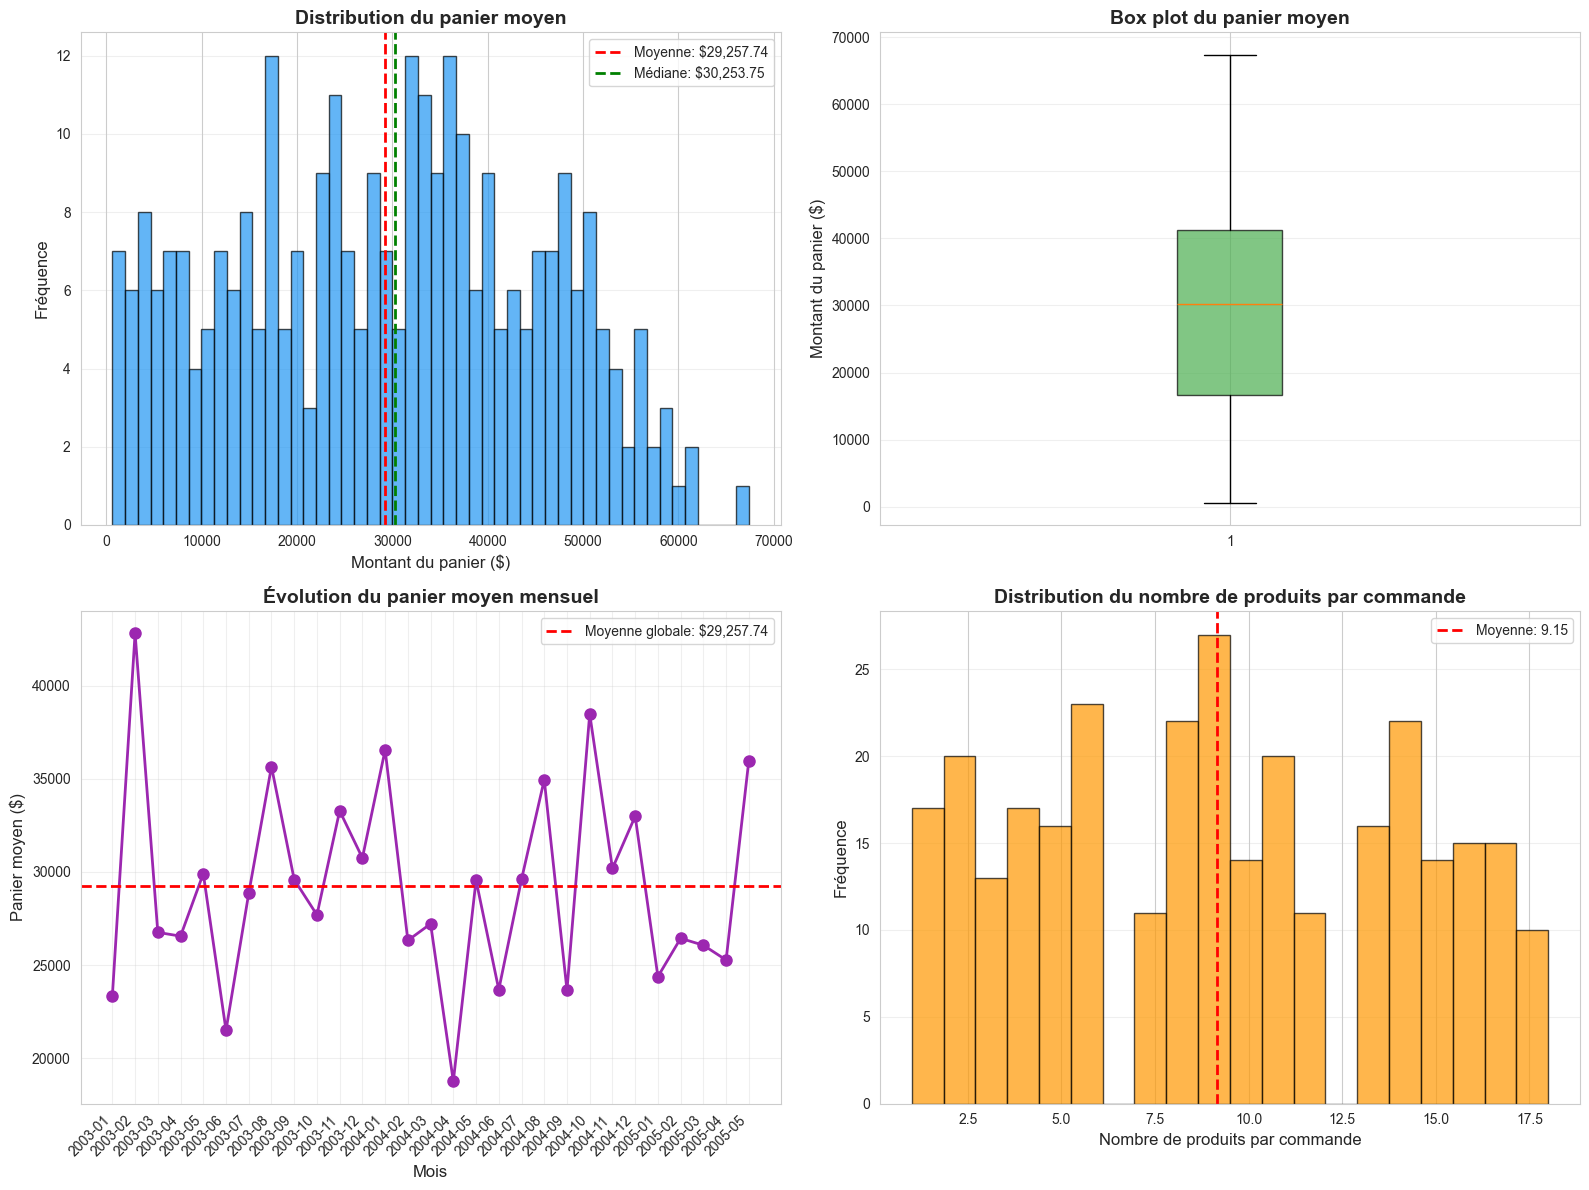

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogramme de la distribution du panier moyen
axes[0, 0].hist(basket_analysis['montant_total'], bins=50, color='#2196F3', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(panier_moyen_global, color='red', linestyle='--', linewidth=2, label=f'Moyenne: ${panier_moyen_global:,.2f}')
axes[0, 0].axvline(panier_median, color='green', linestyle='--', linewidth=2, label=f'Médiane: ${panier_median:,.2f}')
axes[0, 0].set_xlabel('Montant du panier ($)', fontsize=12)
axes[0, 0].set_ylabel('Fréquence', fontsize=12)
axes[0, 0].set_title('Distribution du panier moyen', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')

# 2. Box plot du panier moyen
axes[0, 1].boxplot(basket_analysis['montant_total'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#4CAF50', alpha=0.7))
axes[0, 1].set_ylabel('Montant du panier ($)', fontsize=12)
axes[0, 1].set_title('Box plot du panier moyen', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# 3. Évolution du panier moyen dans le temps (par mois)
basket_monthly = basket_analysis.groupby(basket_analysis['orderDate'].dt.to_period('M')).agg({
    'montant_total': 'mean',
    'orderNumber': 'count'
}).reset_index()
basket_monthly['orderDate'] = basket_monthly['orderDate'].astype(str)

axes[1, 0].plot(range(len(basket_monthly)), basket_monthly['montant_total'], 
                marker='o', linewidth=2, markersize=8, color='#9C27B0')
axes[1, 0].axhline(panier_moyen_global, color='red', linestyle='--', linewidth=2, 
                   label=f'Moyenne globale: ${panier_moyen_global:,.2f}')
axes[1, 0].set_xlabel('Mois', fontsize=12)
axes[1, 0].set_ylabel('Panier moyen ($)', fontsize=12)
axes[1, 0].set_title('Évolution du panier moyen mensuel', fontsize=14, fontweight='bold')
axes[1, 0].set_xticks(range(len(basket_monthly)))
axes[1, 0].set_xticklabels(basket_monthly['orderDate'], rotation=45, ha='right')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Distribution du nombre de produits par commande
axes[1, 1].hist(basket_analysis['nb_produits'], bins=20, color='#FF9800', edgecolor='black', alpha=0.7)
axes[1, 1].axvline(basket_analysis['nb_produits'].mean(), color='red', linestyle='--', linewidth=2, 
                   label=f'Moyenne: {basket_analysis["nb_produits"].mean():.2f}')
axes[1, 1].set_xlabel('Nombre de produits par commande', fontsize=12)
axes[1, 1].set_ylabel('Fréquence', fontsize=12)
axes[1, 1].set_title('Distribution du nombre de produits par commande', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Interprétation métier des visualisations du panier moyen

### Distribution du panier moyen

**Concentration entre $20K-$40K :**
- **Pic principal** : La majorité des commandes se situe entre $25K-$35K
- **Moyenne et médiane proches** : Distribution relativement symétrique, pas de forte asymétrie
- **Queue de distribution** : Quelques commandes très élevées (>$60K) mais rares

**Insight** : Comportement d'achat prévisible avec une base solide autour de $30K.

### Box plot - Dispersion des paniers

**Quartiles :**
- **Q1 : ~$17K** : 25% des commandes en dessous
- **Médiane : ~$30K** : Valeur centrale
- **Q3 : ~$40K** : 75% des commandes en dessous
- **Whiskers jusqu'à ~$68K** : Valeurs extrêmes mais acceptables

**Insight** : 50% des commandes se concentrent entre $17K-$40K, zone cible pour optimiser les ventes.

### Évolution mensuelle du panier moyen

**Variations importantes :**
- **Pic en mars 2003 : $42K+** : Panier exceptionnel, possible événement promotionnel ou commande importante
- **Pic en octobre 2004 : ~$40K** : Saisonnalité de fin d'année confirmée
- **Creux en mai 2004 : <$20K** : Baisse significative, à investiguer

**Tendance** : Fluctuations importantes mais moyenne globale stable autour de $29K.

### Distribution du nombre de produits

**Pic entre 7,5-10 produits :**
- **Comportement typique** : La plupart des commandes contient 8-10 produits
- **Moyenne : 9,15 produits** : Comportement cohérent et prévisible
- **Distribution en cloche** : Peu de commandes avec très peu ou très beaucoup de produits

**Insight** : Les clients ont un comportement d'achat régulier, facilitant la planification des stocks.

## Identification des produits achetés ensemble

Analyse des co-occurrences de produits dans les mêmes commandes pour identifier les associations fréquentes.

In [6]:
# Pour chaque commande, on extrait la liste des produits
orders_products = df_orders.groupby('orderNumber')['productCode'].apply(list).reset_index()

# Calcul des paires de produits achetés ensemble
product_pairs = []
for _, row in orders_products.iterrows():
    products = row['productCode']
    # Générer toutes les paires de produits dans cette commande
    if len(products) > 1:
        pairs = list(combinations(sorted(products), 2))
        product_pairs.extend(pairs)

# Compter la fréquence de chaque paire
pair_counter = Counter(product_pairs)

# Créer un DataFrame avec les paires les plus fréquentes
top_pairs = pd.DataFrame(pair_counter.most_common(50), columns=['paire', 'frequence'])

# Ajouter les noms des produits
def get_product_info(product_code):
    product_info = df_orders[df_orders['productCode'] == product_code].iloc[0]
    return product_info['productName'], product_info['productLine']

top_pairs['produit1_code'] = top_pairs['paire'].apply(lambda x: x[0])
top_pairs['produit2_code'] = top_pairs['paire'].apply(lambda x: x[1])
top_pairs['produit1_nom'] = top_pairs['produit1_code'].apply(lambda x: get_product_info(x)[0])
top_pairs['produit2_nom'] = top_pairs['produit2_code'].apply(lambda x: get_product_info(x)[0])
top_pairs['produit1_gamme'] = top_pairs['produit1_code'].apply(lambda x: get_product_info(x)[1])
top_pairs['produit2_gamme'] = top_pairs['produit2_code'].apply(lambda x: get_product_info(x)[1])

# Calculer le pourcentage de co-occurrence
total_orders = len(orders_products)
top_pairs['pourcentage'] = (top_pairs['frequence'] / total_orders * 100).round(2)

print(f"Nombre total de commandes analysées : {total_orders}")
print(f"Nombre de paires de produits uniques : {len(pair_counter)}")
print(f"\nTop 10 des paires de produits les plus fréquemment achetées ensemble :")
print("=" * 100)
display(top_pairs[['produit1_nom', 'produit2_nom', 'produit1_gamme', 'produit2_gamme', 'frequence', 'pourcentage']].head(10))

Nombre total de commandes analysées : 303
Nombre de paires de produits uniques : 1846

Top 10 des paires de produits les plus fréquemment achetées ensemble :


,produit1_nom,produit2_nom,produit1_gamme,produit2_gamme,frequence,pourcentage
0,1934 Ford V8 Coupe,18th Century Vintage Horse Carriage,Vintage Cars,Vintage Cars,26,8.58
1,1974 Ducati 350 Mk3 Desmo,2002 Yamaha YZR M1,Motorcycles,Motorcycles,26,8.58
2,1964 Mercedes Tour Bus,1992 Ferrari 360 Spider red,Trucks and Buses,Classic Cars,25,8.25
3,1930 Buick Marquette Phaeton,American Airlines: B767-300,Vintage Cars,Planes,25,8.25
4,1996 Moto Guzzi 1100i,1936 Harley Davidson El Knucklehead,Motorcycles,Motorcycles,25,8.25
5,1968 Ford Mustang,1970 Plymouth Hemi Cuda,Classic Cars,Classic Cars,25,8.25
6,1982 Ducati 900 Monster,1974 Ducati 350 Mk3 Desmo,Motorcycles,Motorcycles,25,8.25
7,1932 Model A Ford J-Coupe,1939 Chevrolet Deluxe Coupe,Vintage Cars,Vintage Cars,24,7.92
8,1937 Lincoln Berline,1936 Mercedes-Benz 500K Special Roadster,Vintage Cars,Vintage Cars,24,7.92
9,1952 Alpine Renault 1300,1940 Ford Pickup Truck,Classic Cars,Trucks and Buses,24,7.92


## Interprétation  des associations de produits

### Top 10 paires de produits

**Fréquences élevées (8,25-8,58%) :**
- **2 paires à 26 fois (8,58%)** : Associations très fortes
  - Vintage Cars : 1934 Ford V8 Coupe + 18th Century Vintage Horse Carriage
  - Motorcycles : 1974 Ducati 350 Mk3 Desmo + 2002 Yamaha YZR M1
- **5 paires à 25 fois (8,25%)** : Associations solides
- **3 paires à 24 fois (7,92%)** : Associations modérées mais significatives

**Patterns identifiés :**
- **Associations intra-gamme dominantes** : Les clients achètent souvent des produits de la même gamme ensemble
- **Vintage Cars** : Forte cohésion (3 paires dans le top 10)
- **Motorcycles** : Forte cohésion (2 paires dans le top 10)
- **Associations inter-gammes** : Quelques associations entre gammes différentes (ex: Trucks + Classic Cars)

**Insights stratégiques :**
- **Cross-selling intra-gamme efficace** : Recommander des produits de la même gamme fonctionne
- **Opportunités inter-gammes** : Développer des stratégies pour associer Classic Cars + Trucks, Vintage Cars + Planes
- **1846 paires uniques** : Grande diversité d'associations possibles, potentiel d'optimisation important


In [7]:
# Filtrer les paires de produits de la même gamme
same_line_pairs = top_pairs[top_pairs['produit1_gamme'] == top_pairs['produit2_gamme']].copy()

# Grouper par gamme
same_line_stats = same_line_pairs.groupby('produit1_gamme').agg({
    'frequence': 'sum',
    'paire': 'count'
}).reset_index()
same_line_stats.columns = ['gamme', 'total_frequence', 'nb_paires']
same_line_stats = same_line_stats.sort_values('total_frequence', ascending=False)

print("Associations de produits de la même gamme :")
print("=" * 80)
display(same_line_stats)

# Top paires par gamme
print("\nTop 3 paires par gamme :")
print("=" * 80)
for gamme in same_line_stats['gamme'].head(5):
    gamme_pairs = same_line_pairs[same_line_pairs['produit1_gamme'] == gamme].head(3)
    print(f"\n{gamme} :")
    for _, row in gamme_pairs.iterrows():
        print(f"  - {row['produit1_nom']} + {row['produit2_nom']} : {row['frequence']} fois ({row['pourcentage']}%)")

Associations de produits de la même gamme :


,gamme,total_frequence,nb_paires
0,Classic Cars,282,12
1,Motorcycles,170,7
4,Vintage Cars,141,6
2,Planes,46,2
3,Trucks and Buses,44,2



Top 3 paires par gamme :

Classic Cars :
  - 1968 Ford Mustang + 1970 Plymouth Hemi Cuda : 25 fois (8.25%)
  - 1970 Dodge Coronet + 1992 Porsche Cayenne Turbo Silver : 24 fois (7.92%)
  - 1969 Dodge Charger + 1948 Porsche 356-A Roadster : 24 fois (7.92%)

Motorcycles :
  - 1974 Ducati 350 Mk3 Desmo + 2002 Yamaha YZR M1 : 26 fois (8.58%)
  - 1996 Moto Guzzi 1100i + 1936 Harley Davidson El Knucklehead : 25 fois (8.25%)
  - 1982 Ducati 900 Monster + 1974 Ducati 350 Mk3 Desmo : 25 fois (8.25%)

Vintage Cars :
  - 1934 Ford V8 Coupe + 18th Century Vintage Horse Carriage : 26 fois (8.58%)
  - 1932 Model A Ford J-Coupe + 1939 Chevrolet Deluxe Coupe : 24 fois (7.92%)
  - 1937 Lincoln Berline + 1936 Mercedes-Benz 500K Special Roadster : 24 fois (7.92%)

Planes :
  - Corsair F4U ( Bird Cage) + American Airlines: MD-11S : 24 fois (7.92%)
  - P-51-D Mustang + 1928 British Royal Navy Airplane : 22 fois (7.26%)

Trucks and Buses :
  - 1958 Setra Bus + 1940 Ford Pickup Truck : 22 fois (7.26%)
  - 19

## Visualisation des associations de produits

Graphiques montrant les produits les plus fréquemment achetés ensemble.

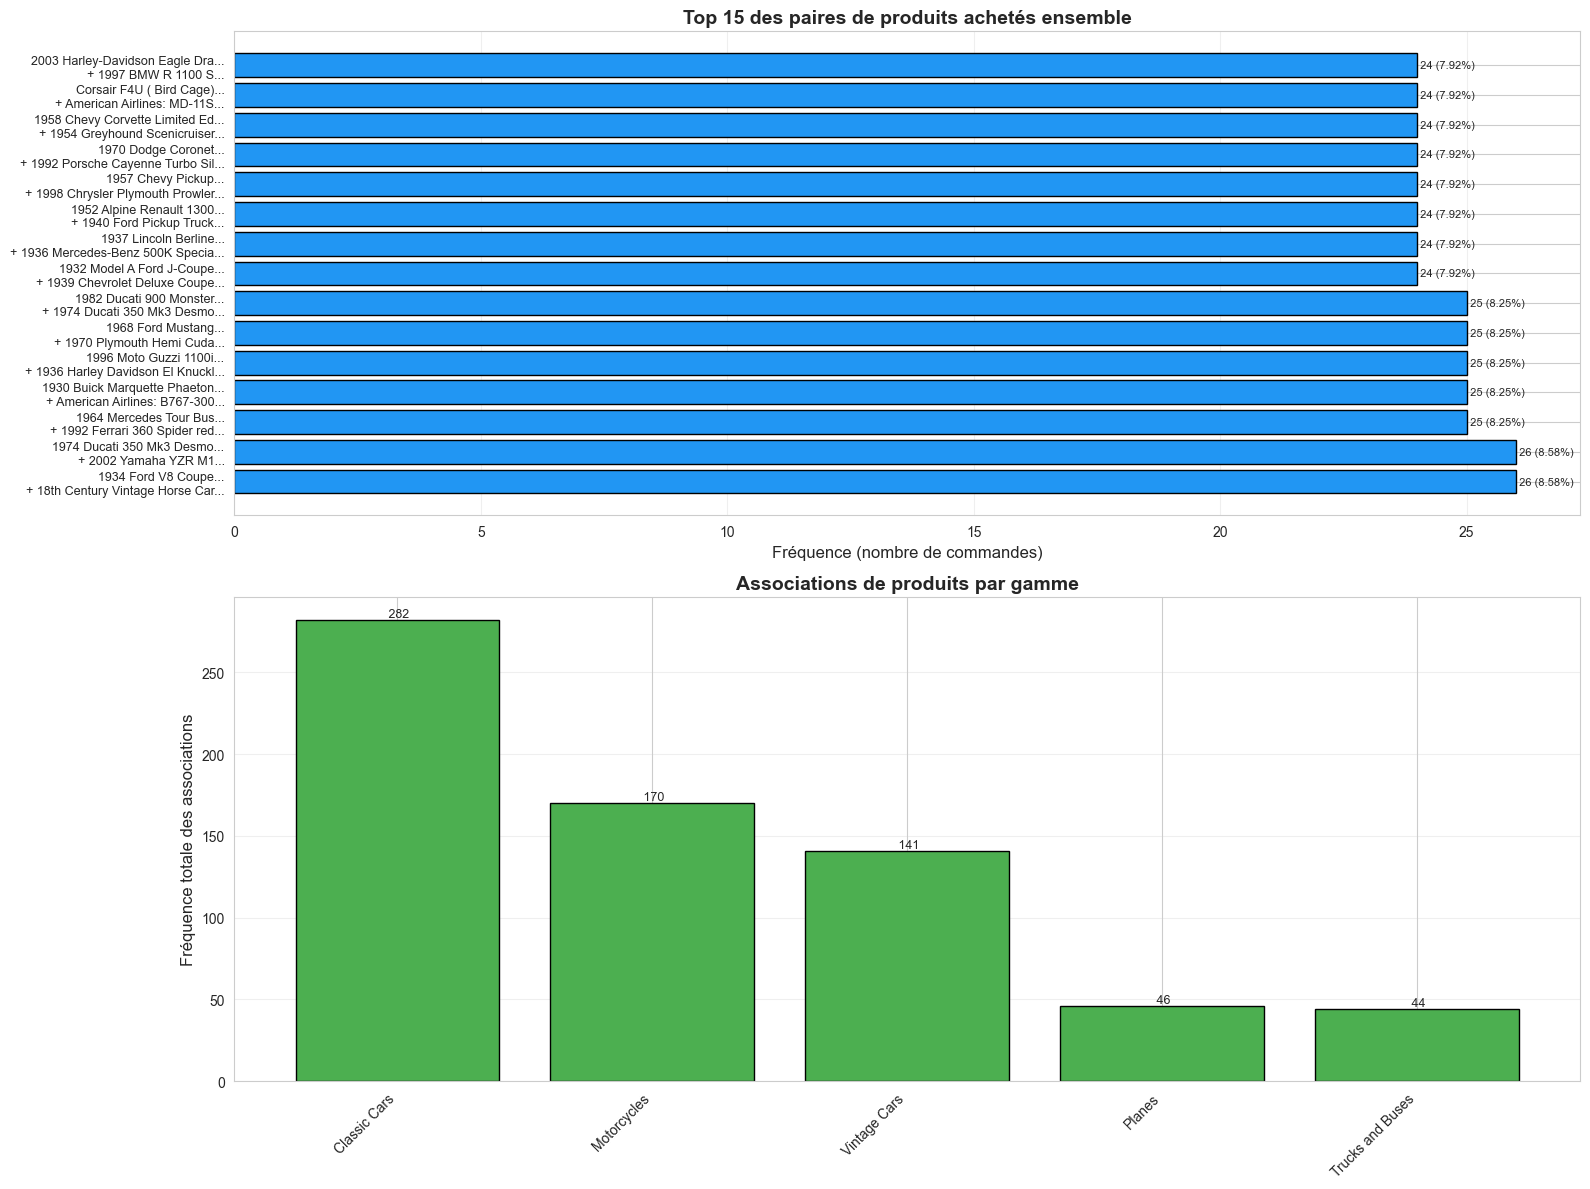

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# 1. Top 15 paires de produits les plus fréquentes
top_15 = top_pairs.head(15).copy()
top_15['paire_label'] = top_15.apply(
    lambda x: f"{x['produit1_nom'][:30]}...\n+ {x['produit2_nom'][:30]}...", axis=1
)

axes[0].barh(range(len(top_15)), top_15['frequence'], color='#2196F3', edgecolor='black')
axes[0].set_yticks(range(len(top_15)))
axes[0].set_yticklabels(top_15['paire_label'], fontsize=9)
axes[0].set_xlabel('Fréquence (nombre de commandes)', fontsize=12)
axes[0].set_title('Top 15 des paires de produits achetés ensemble', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='x')

# Ajouter les valeurs sur les barres
for i, (idx, row) in enumerate(top_15.iterrows()):
    axes[0].text(row['frequence'], i, f" {row['frequence']} ({row['pourcentage']}%)", 
                va='center', fontsize=8)

# 2. Associations par gamme de produits
axes[1].bar(range(len(same_line_stats)), same_line_stats['total_frequence'], 
            color='#4CAF50', edgecolor='black')
axes[1].set_xticks(range(len(same_line_stats)))
axes[1].set_xticklabels(same_line_stats['gamme'], rotation=45, ha='right', fontsize=10)
axes[1].set_ylabel('Fréquence totale des associations', fontsize=12)
axes[1].set_title('Associations de produits par gamme', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Ajouter les valeurs sur les barres
for i, (idx, row) in enumerate(same_line_stats.iterrows()):
    axes[1].text(i, row['total_frequence'], f" {row['total_frequence']}", 
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Interprétation des visualisations d'associations

### Top 15 paires de produits

**Fréquences très proches (24-26 fois) :**
- **Écart faible** : Les top associations sont très proches en fréquence (24-26 fois)
- **Pourcentages stables** : Entre 7,92% et 8,58%, pas de paire vraiment dominante
- **Diversité des gammes** : Toutes les gammes sont représentées dans le top 15

**Insight** : Pas de "paire magique" unique, mais plusieurs associations fortes à exploiter simultanément.

### Associations par gamme

**Classic Cars : 282 associations (dominance claire) :**
- **2,4x plus que Motorcycles** : Écart significatif
- **6,1x plus que Planes** : Classic Cars est la gamme phare pour les associations

**Répartition inégale :**
- **Top 3 gammes** (Classic Cars, Motorcycles, Vintage Cars) représentent 593 associations sur 683 totales (87%)
- **Bottom 2 gammes** (Planes, Trucks) représentent seulement 90 associations (13%)

**Implications stratégiques :**
- **Concentrer les efforts** sur Classic Cars, Motorcycles et Vintage Cars
- **Diversifier les associations** pour Planes et Trucks (opportunité d'amélioration)
- **Stratégie de merchandising** : Mettre en avant les produits Classic Cars ensemble, créer des packs

## Résumé et insights

Synthèse des principales découvertes sur le panier moyen et les associations de produits.

In [ ]:
# Créer un tableau récapitulatif
summary_data = {
    'Métrique': [
        'Panier moyen global',
        'Panier médian',
        'Nombre moyen de produits par commande',
        'Nombre total de paires de produits uniques',
        'Paire la plus fréquente',
        'Fréquence de la paire la plus fréquente',
        'Gamme avec le plus d\'associations'
    ],
    'Valeur': [
        f'${panier_moyen_global:,.2f}',
        f'${panier_median:,.2f}',
        f'{basket_analysis["nb_produits"].mean():.2f}',
        f'{len(pair_counter)}',
        f'{top_pairs.iloc[0]["produit1_nom"][:40]}... + {top_pairs.iloc[0]["produit2_nom"][:40]}...',
        f'{top_pairs.iloc[0]["frequence"]} fois ({top_pairs.iloc[0]["pourcentage"]}%)',
        f'{same_line_stats.iloc[0]["gamme"]} ({same_line_stats.iloc[0]["total_frequence"]} associations)'
    ]
}

summary_df = pd.DataFrame(summary_data)

print("=" * 100)
print("RÉSUMÉ DE L'ANALYSE DE PANIER MOYEN ET ASSOCIATIONS")
print("=" * 100)
display(summary_df)

RÉSUMÉ DE L'ANALYSE DE PANIER MOYEN ET ASSOCIATIONS


,Métrique,Valeur
0,Panier moyen global,"$29,257.74"
1,Panier médian,"$30,253.75"
2,Nombre moyen de produits par commande,9.15
3,Nombre total de paires de produits uniques,1846
4,Paire la plus fréquente,1934 Ford V8 Coupe... + 18th Century Vintage H...
5,Fréquence de la paire la plus fréquente,26 fois (8.58%)
6,Gamme avec le plus d'associations,Classic Cars (282 associations)


## Conclusion : Synthèse et recommandations stratégiques

### Points clés de l'analyse

**1. Panier moyen élevé et stable**
- **$29,258** : Positionnement premium confirmé
- **9,15 produits/commande** : Clients ouverts au cross-selling
- **Distribution concentrée** : Comportement prévisible entre $20K-$40K

**2. Associations de produits identifiées**
- **1846 paires uniques** : Grande diversité d'opportunités
- **Top associations à 8,58%** : Fréquences significatives mais pas de paire dominante
- **Classic Cars leader** : 282 associations, gamme phare pour le cross-selling

**3. Patterns comportementaux**
- **Associations intra-gamme dominantes** : Clients achètent souvent des produits de la même gamme
- **Quelques associations inter-gammes** : Opportunités à développer

### Recommandations prioritaires

**1. Optimisation du cross-selling**
- **Recommandations automatiques** : Mettre en avant les top 15 paires identifiées
- **Packs produits** : Créer des bundles pour les associations les plus fréquentes (ex: Vintage Cars packs)
- **Merchandising** : Disposition en magasin/online basée sur les associations

**2. Stratégie par gamme**
- **Classic Cars** : Maximiser les recommandations (282 associations)
- **Motorcycles & Vintage Cars** : Développer les associations (170 et 141)
- **Planes & Trucks** : Analyser pourquoi peu d'associations et développer des stratégies ciblées

**3. Segmentation client**
- **Clients à panier élevé** (>$40K) : Offres premium et associations haut de gamme
- **Clients à panier moyen** ($20K-$40K) : Focus sur les top associations identifiées
- **Clients à panier faible** (<$20K) : Stratégies d'upselling vers panier moyen

**4. Actions opérationnelles**
- **Formation équipe** : Connaître les top associations pour recommandations en magasin
- **Campagnes marketing** : Promouvoir les paires identifiées (ex: "Clients qui ont acheté X ont aussi acheté Y")
- **Suivi des performances** : Mesurer l'impact des recommandations sur le panier moyen